# 01 · Exploratory Data Analysis — Digital Manipulation Radar

**Question.** Can we tell accounts that belong to a state-backed influence operation (IO) apart from ordinary
repliers, using only how they reply (timing, text, profile, who they reply with)?

**Data.** OSoMe *Coordinated reply attacks* dataset (Zenodo 10.5281/zenodo.13896308, CC BY 4.0): replies on
Twitter 2018–2021 to tweets attacked by accounts that Twitter later removed as part of state-backed operations.
The labels come from Twitter's own takedown lists, not from us.

Each section ends with a **finding** and the **decision** it led to in preprocessing, modelling or evaluation.

> Run from the repo root after `python scripts/download_data.py` and `python -m radar.pipeline`
> (the pipeline writes `artifacts/accounts.pkl`: the released features joined with each account's campaign
> and its co-reply network features).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from radar import config as C
warnings.filterwarnings("ignore")

RAW, ART = ROOT / "data" / "raw", ROOT / "artifacts"
NORMAL, IO = "#2a78d6", "#eb6834"          # one colour per class, used in every chart
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": .6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8984", "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False})
pd.set_option("display.float_format", "{:,.3f}".format)

def by_class(ax, col, data, bins, log=False, xlabel=None):
    # two overlaid histograms (each class sums to 100 %): normal vs IO
    for lab, name, c in [(0, "normal", NORMAL), (1, "IO (operation)", IO)]:
        x = data.loc[data[C.COL_LABEL] == lab, col].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(x, bins=bins, weights=np.full(len(x), 100 / len(x)), histtype="step", linewidth=2, color=c,
                label=f"{name}  (median {x.median():,.2f})")
    if log: ax.set_xscale("log")
    ax.set_xlabel(xlabel or col); ax.set_ylabel("% of the class's accounts"); ax.legend(fontsize=8)

## 1 · The files and their size

In [2]:
replies = pd.read_pickle(ART / "replies.pkl")            # = poster_tweetid_campaign_type.csv
acc = pd.read_pickle(ART / "accounts.pkl")               # released features + campaign + network features
delays = pd.read_csv(RAW / "RQ1_time_difference_of_reply.csv")
pd.DataFrame({
    "rows": [len(replies), len(acc), len(delays)],
    "one row is": ["a reply to a target or control tweet", "a replying account (76 features)",
                   "one reply and its delay"],
}, index=["poster_tweetid_campaign_type.csv", "RQ3_replier_classifier_features.csv",
          "RQ1_time_difference_of_reply.csv"])

,rows,one row is
poster_tweetid_campaign_type.csv,2673091,a reply to a target or control tweet
RQ3_replier_classifier_features.csv,794645,a replying account (76 features)
RQ1_time_difference_of_reply.csv,2147936,one reply and its delay


In [3]:
print(f"replies: {len(replies):,} | accounts: {acc[C.COL_USER].nunique():,} | tweets replied to: {replies[C.COL_TWEET].nunique():,}")
print("tweet type:", replies[C.COL_TYPE].value_counts().to_dict())
print("duplicate accounts in the feature file:", acc[C.COL_USER].duplicated().sum())

replies: 2,673,091 | accounts: 794,645 | tweets replied to: 7,732
tweet type: {'target': 2160484, 'control': 512607}
duplicate accounts in the feature file: 0


**Finding.** 2,673,091 replies from 794,645 accounts to 7,732 tweets: 3,866 *target* tweets (attacked by an operation) and 3,866 *control* tweets. Every account appears exactly once in the feature file, so one row = one account and there is nothing to de-duplicate.

**Decision.** The unit we classify is the **account**, not the single reply: an operation is visible in how an account behaves across many replies.

## 2 · Class imbalance — the needle in the haystack

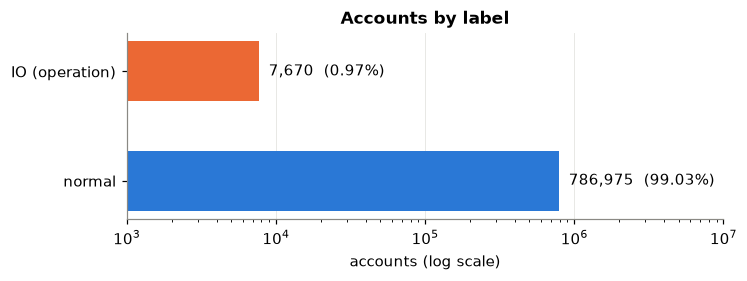

,accounts,share
replier_label,,
normal,786975,0.990
IO (operation),7670,0.010


In [4]:
counts = acc[C.COL_LABEL].value_counts().rename({0: "normal", 1: "IO (operation)"})
share = counts / counts.sum()
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.barh(counts.index, counts.values, color=[NORMAL, IO], height=.55)
for i, (n, s) in enumerate(zip(counts.values, share.values)):
    ax.text(n, i, f"  {n:,}  ({s:.2%})", va="center")
ax.set_xscale("log"); ax.set_xlim(1e3, 1e7); ax.set_xlabel("accounts (log scale)")
ax.set_title("Accounts by label"); ax.grid(axis="y", visible=False)
plt.show()
pd.DataFrame({"accounts": counts, "share": share})

**Finding.** Only **7,670 of 794,645 accounts (0.97 %)** are operation accounts — about 1 in 100. A model that says "normal" for everyone is 99 % accurate and useless.

**Decisions.**
- **Metric:** accuracy is meaningless here, so we evaluate with **PR-AUC** (how well the model ranks the rare IO accounts to the top) and **precision@100 / @500** (of the top accounts a person would review, how many are real). ROC-AUC is reported but not used to choose, because it looks good even when the top of the list is full of false alarms.
- **Training:** we keep all IO accounts and **downsample normal accounts to 10 per IO account** in the training folds only. The test campaign always keeps its real, tiny IO share.
- **Product:** with this imbalance a fixed yes/no cut-off produces many false alarms, so the app **ranks accounts for a person to review** instead of auto-labelling them.

## 3 · Campaigns — six very different test sets

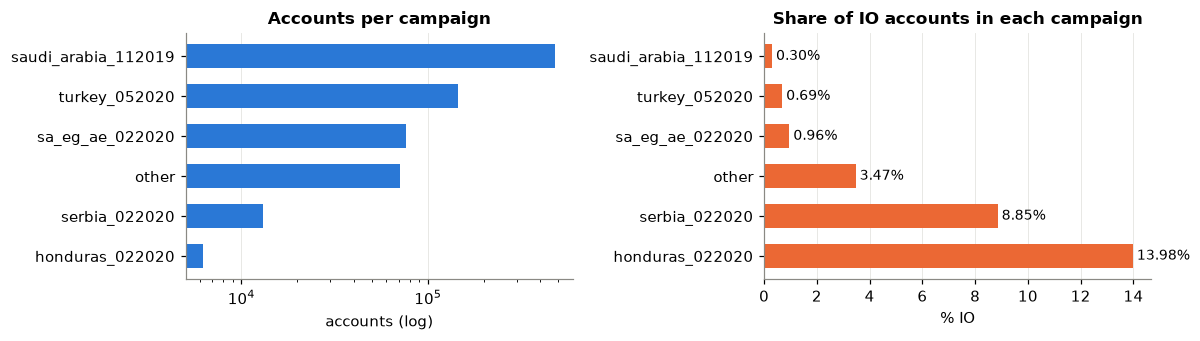

,accounts,io,io_share,target tweets
campaign_group,,,,
saudi_arabia_112019,482243,1454,0.003,1356
turkey_052020,145585,999,0.007,690
sa_eg_ae_022020,76808,735,0.010,861
other,70738,2455,0.035,1069
serbia_022020,13011,1152,0.089,1163
honduras_022020,6260,875,0.140,222


In [5]:
camp = (acc.groupby("campaign_group")
          .agg(accounts=(C.COL_LABEL, "size"), io=(C.COL_LABEL, "sum"))
          .assign(io_share=lambda d: d.io / d.accounts)
          .sort_values("accounts", ascending=False))
tweets = (replies[replies[C.COL_TYPE] == "target"].merge(acc[[C.COL_USER, "campaign_group"]], on=C.COL_USER)
          .groupby("campaign_group")[C.COL_TWEET].nunique().rename("target tweets"))
camp = camp.join(tweets)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].barh(camp.index, camp.accounts, color=NORMAL, height=.6); axes[0].set_xscale("log")
axes[0].set_title("Accounts per campaign"); axes[0].set_xlabel("accounts (log)"); axes[0].invert_yaxis()
axes[1].barh(camp.index, camp.io_share * 100, color=IO, height=.6); axes[1].invert_yaxis()
for i, v in enumerate(camp.io_share * 100): axes[1].text(v, i, f" {v:.2f}%", va="center", fontsize=9)
axes[1].set_title("Share of IO accounts in each campaign"); axes[1].set_xlabel("% IO")
for a in axes: a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
camp

**Finding.** The campaigns are very different in size and in how rare IO accounts are: Saudi Arabia has 482,243 accounts with only **0.30 %** IO; Honduras has 6,260 accounts with **14 %** IO — a 46× difference. Small campaigns are pooled into `other` (as in the original paper).

**Decisions.**
- Results are reported **per campaign**, and PR-AUC is always read next to the campaign's prevalence (a PR-AUC of 0.07 on Saudi is 23× better than random; the same number on Honduras would be worse than random).
- The headline number is the **mean over campaigns**, so the huge Saudi campaign does not drown the others.

## 4 · Replies per tweet — target vs control

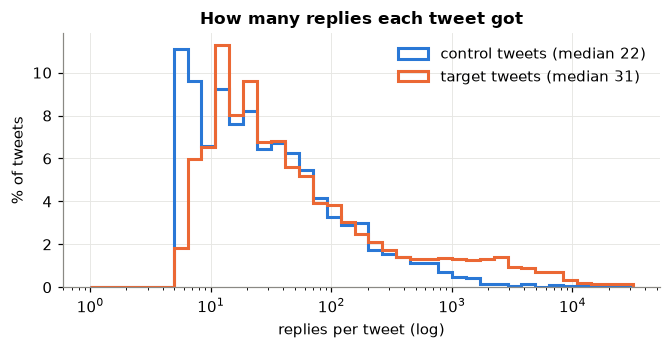

replies                       io_replies                        
          count    mean median    max      count   mean median       max
type                                                                    
control    3866 132.594 22.000  20951       3866  0.000  0.000     0.000
target     3866 558.842 31.000  46979       3866 17.427  7.000 5,788.000

In [6]:
per_tweet = replies.groupby([C.COL_TWEET, C.COL_TYPE]).size().rename("replies").reset_index()
io_per_tweet = replies[replies[C.COL_LABEL] == 1].groupby(C.COL_TWEET).size()
per_tweet["io_replies"] = per_tweet[C.COL_TWEET].map(io_per_tweet).fillna(0)
fig, ax = plt.subplots(figsize=(7, 3))
for t, c in [("control", NORMAL), ("target", IO)]:
    x = per_tweet.loc[per_tweet[C.COL_TYPE] == t, "replies"]
    ax.hist(x, bins=np.logspace(0, 4.5, 40), histtype="step", linewidth=2, color=c, weights=np.full(len(x), 100 / len(x)),
            label=f"{t} tweets (median {x.median():.0f})")
ax.set_xscale("log"); ax.set_xlabel("replies per tweet (log)"); ax.set_ylabel("% of tweets"); ax.legend()
ax.set_title("How many replies each tweet got")
plt.show()
per_tweet.groupby(C.COL_TYPE)[["replies", "io_replies"]].agg(["count", "mean", "median", "max"])

**Finding.** Attacked (target) tweets draw more replies than control tweets (median 31 vs 22), and a median of **7 replies from operation accounts** each; some viral targets have tens of thousands of replies (max 46,979). Control tweets have no IO replies at all — they exist so that normal accounts are seen in a normal setting too.

**Decisions.**
- The co-reply network is built from **target tweets only**, and tweets with more than **2,000 repliers are skipped**: a viral tweet would link thousands of unrelated accounts into one giant clique.
- An account must reply to at least 2 target tweets, and two accounts must share at least 3 tweets to be linked (2 shared tweets gave 4.1 M mostly random links; 3 gives 831 k).

## 5 · Reply delay — and a unit surprise

The datasheet calls the column `diff_min` (minutes). A tweet ID is a *Snowflake* ID: its top bits are the time
it was posted (`(id >> 22) + 1288834974657` ms). So we can recompute each delay ourselves and check the unit.

In [7]:
TW = 1288834974657
r = (replies[[C.COL_TWEET, C.COL_REPLY]].merge(delays.drop_duplicates(C.COL_REPLY), on=C.COL_REPLY)
       .sample(50_000, random_state=0))
ms = lambda ids: (ids.to_numpy(dtype="int64") >> 22) + TW
gap_ms = ms(r[C.COL_REPLY]) - ms(r[C.COL_TWEET])
pd.DataFrame({
    "unit tested": ["minutes, rounded up", "hours, rounded up"],
    "rows where it matches diff_min": [(np.ceil(gap_ms / 6e4) == r["diff_min"].to_numpy()).mean(),
                                       (np.ceil(gap_ms / 3.6e6) == r["diff_min"].to_numpy()).mean()]
}).style.format({"rows where it matches diff_min": "{:.1%}"}).hide(axis="index")

unit tested,rows where it matches diff_min
"minutes, rounded up",0.7%
"hours, rounded up",96.5%


**Finding — the column is not in minutes.** Recomputing the delay from the Snowflake IDs matches `diff_min` on **96.5 %** of replies when measured in **hours, rounded up**, and on only **0.7 %** in minutes. The datasheet's name is misleading.

**Decision.** Everything we show and compute uses **hours**. The simple-input model in the app rebuilds this feature from a user's plain replies file exactly the same way (`ceil(gap / 1 hour)`), otherwise its inputs would be on a different scale from the training data.

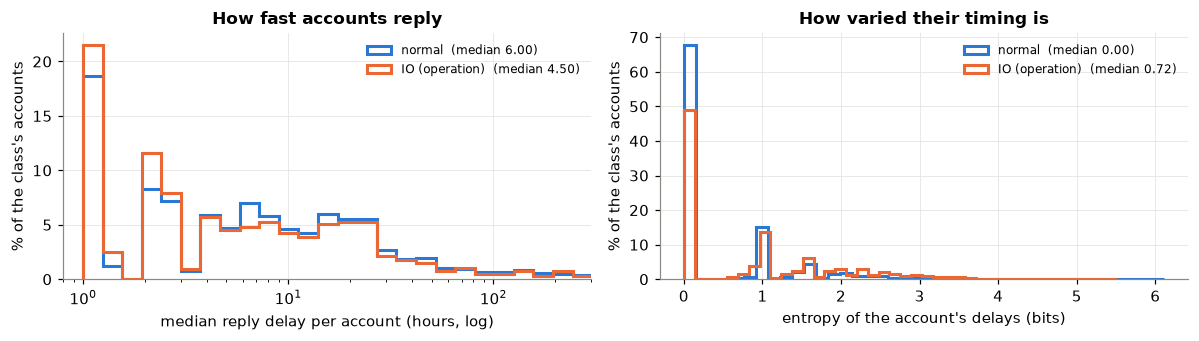

,mean_diff_min,50%_diff_min,min_diff_min,entropy_diff_min
replier_label,,,,
normal,7.750,6.000,4.000,-0.000
IO,6.750,4.500,2.000,0.722


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
by_class(axes[0], "50%_diff_min", acc, bins=np.logspace(0, 4.2, 45), log=True,
         xlabel="median reply delay per account (hours, log)")
axes[0].set_xlim(.8, 300); axes[0].set_title("How fast accounts reply")
by_class(axes[1], "entropy_diff_min", acc, bins=40, xlabel="entropy of the account's delays (bits)")
axes[1].set_title("How varied their timing is")
plt.tight_layout(); plt.show()
acc.groupby(C.COL_LABEL)[["mean_diff_min", "50%_diff_min", "min_diff_min", "entropy_diff_min"]].median().rename(index={0: "normal", 1: "IO"})

**Finding.** Operation accounts reply a little faster (median of medians 4.5 h vs 6 h; fastest reply 2 h vs 4 h), but the two distributions overlap almost completely. Most normal accounts (59 %) replied only once, so the spread of their timing (entropy) is 0; IO accounts reply more often, so they have a timing pattern to measure.

**Decision.** Timing is a weak signal on its own; it is kept as one feature group among several, and the model has to combine it with the others.

## 6 · Text similarity

`*_cosine` = how similar an account's replies are to the other replies on the same tweet (LaBSE sentence
embeddings, computed by the dataset authors).

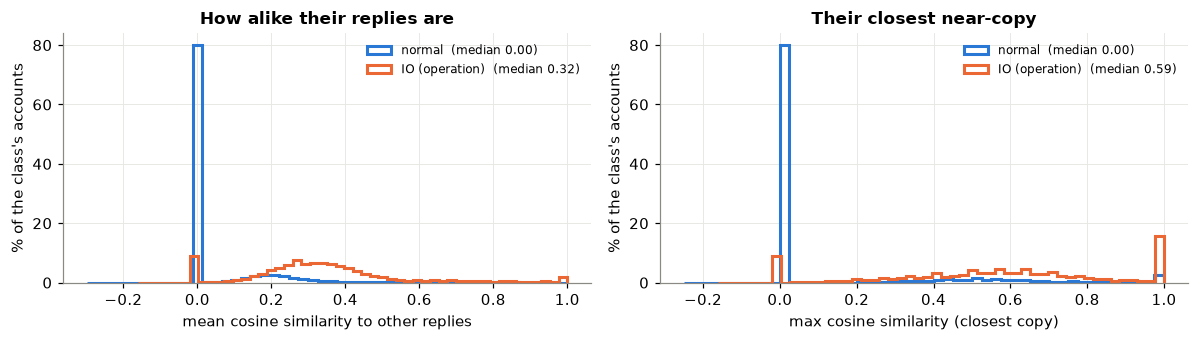

replier_label           normal        IO
mean_cosine count  786,975.000 7,670.000
            mean         0.050     0.338
            median       0.000     0.317
max_cosine  count  786,975.000 7,670.000
            mean         0.122     0.576
            median       0.000     0.590

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
by_class(axes[0], "mean_cosine", acc, bins=50, xlabel="mean cosine similarity to other replies")
axes[0].set_title("How alike their replies are")
by_class(axes[1], "max_cosine", acc, bins=50, xlabel="max cosine similarity (closest copy)")
axes[1].set_title("Their closest near-copy")
plt.tight_layout(); plt.show()
acc.groupby(C.COL_LABEL)[["mean_cosine", "max_cosine"]].agg(["count", "mean", "median"]).T.rename(columns={0: "normal", 1: "IO"})

In [10]:
n_rep = replies.groupby(C.COL_USER).size()
(acc.assign(cosine_is_zero=acc["mean_cosine"] == 0, one_reply=acc[C.COL_USER].map(n_rep) == 1)
    .groupby(C.COL_LABEL)[["cosine_is_zero", "one_reply"]].mean().rename(index={0: "normal", 1: "IO"})
    .style.format("{:.1%}"))

,cosine_is_zero,one_reply
replier_label,,
normal,80.0%,59.0%
IO,9.0%,42.2%


**Finding.** This is by far the strongest signal: operation accounts post replies that look like the other replies on the same tweet (median mean-cosine **0.32** vs **0.00**; median closest copy 0.59 vs 0.00), and on its own `mean_cosine` ranks accounts with a ROC-AUC of **0.90**.

But look at the zeros (table above): **80 % of normal accounts** have a similarity of exactly 0, against 9 % of IO accounts — and this is not just accounts with a single reply. A cosine of exactly 0 is almost never a real measurement; it most likely means *no comparison was made* in the authors' pipeline.

### 6b · How much does the model depend on text similarity?

Because the text features are so strong — and partly placeholders — we re-ran the leave-one-campaign-out
evaluation of the chosen model (Gradient Boosting) **without the nine cosine features** (takes a few minutes).

In [11]:
from radar import model as M
cols = [c for c in acc.columns if c in set(pd.read_json(ART / "run_info.json", typ="series")["feature_columns"])]
no_text, _, _ = M.loco(acc, [c for c in cols if "cosine" not in c], "hgb")
with_text = pd.read_csv(ART / "metrics.csv").query("model == 'hgb' and feature_set == 'behavior (all released features)'")
cmp = (with_text.set_index("held_out")[["prevalence", "pr_auc", "precision_at_100"]]
       .join(no_text.set_index("held_out")[["pr_auc", "precision_at_100"]], rsuffix=" (no text)"))
cmp.loc["mean"] = cmp.mean()
cmp

,prevalence,pr_auc,precision_at_100,pr_auc (no text),precision_at_100 (no text)
held_out,,,,,
honduras_022020,0.140,0.696,0.980,0.231,0.150
other,0.035,0.664,0.990,0.178,0.490
sa_eg_ae_022020,0.010,0.501,0.950,0.034,0.080
saudi_arabia_112019,0.003,0.417,0.870,0.093,0.470
serbia_022020,0.089,0.448,0.900,0.230,0.490
turkey_052020,0.007,0.491,0.910,0.101,0.210
mean,0.047,0.536,0.933,0.144,0.315


**Finding.** Without text similarity the mean PR-AUC falls from **0.54 to 0.14**, and precision@100 from about 9 in 10 to 1–5 in 10 depending on the campaign. Most of the model's power comes from *what* the accounts write being alike, not from timing or profile.

**Decisions.**
- We keep the text features in the main model — copy-paste replies are the core of a coordinated reply attack, and the paper uses them too.
- We state the caveat openly (here, in RESULTS and in the app's About page): part of the signal may come from how the authors computed similarity (the placeholder zeros), so real-world performance on freshly collected data could be lower.
- The app's **simple-input model** cannot rebuild the authors' LaBSE similarity from a plain file, so it runs without it (PR-AUC 0.19) and the app shows near-copied replies separately as evidence for the reviewer.

## 7 · Profile — age, followers, activity

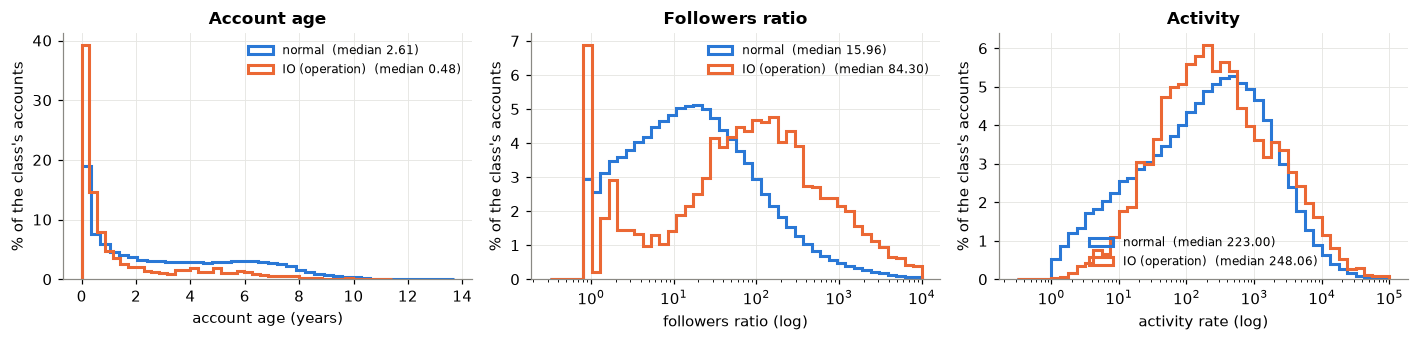

,age,followers_ratio,following_ratio,activity_rate
replier_label,,,,
normal,2.609,15.959,39.942,223.000
IO,0.482,84.302,110.563,248.056


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
by_class(axes[0], "age", acc, bins=40, xlabel="account age (years)")
by_class(axes[1], "followers_ratio", acc, bins=np.logspace(-.5, 4, 45), log=True, xlabel="followers ratio (log)")
by_class(axes[2], "activity_rate", acc, bins=np.logspace(-.5, 5, 45), log=True, xlabel="activity rate (log)")
for a, t in zip(axes, ["Account age", "Followers ratio", "Activity"]): a.set_title(t)
plt.tight_layout(); plt.show()
acc.groupby(C.COL_LABEL)[["age", "followers_ratio", "following_ratio", "activity_rate"]].median().rename(index={0: "normal", 1: "IO"})

**Finding.** Operation accounts are **young** — median age **0.48 years** vs **2.6 years** for normal repliers; many were created shortly before the campaign. They also have higher followers and following ratios (84 vs 16 and 111 vs 40). Activity rates are similar.

**Decision.** Profile features are kept, and account age is one of the few signals a user can supply for their own data, so the simple-input model uses it (`age_years`, followers, following). But profile alone is weak: the profile-only model reaches a mean PR-AUC of only **0.11**.

## 8 · Who replies together — the co-reply network

Two accounts are linked when they replied to at least 3 of the same target tweets (built by `radar.graph`).

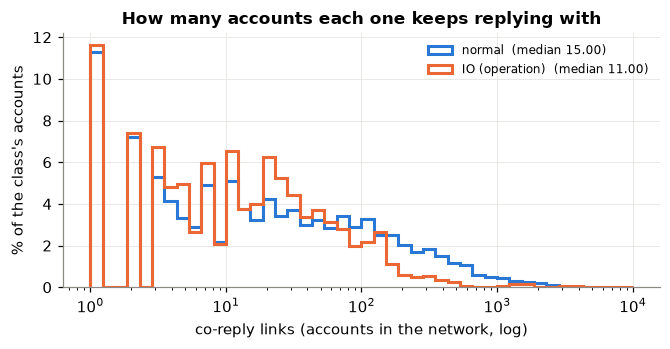

,accounts,in_network,median_links_if_in
replier_label,,,
normal,"786,975",2.3%,15
IO,"7,670",29.4%,11


In [13]:
in_graph = acc["graph_degree"].fillna(0) > 0
t = (acc.assign(in_graph=in_graph).groupby(C.COL_LABEL)
       .agg(accounts=("in_graph", "size"), in_network=("in_graph", "mean"),
            median_links_if_in=("graph_degree", lambda s: s[s > 0].median()))
       .rename(index={0: "normal", 1: "IO"}))
fig, ax = plt.subplots(figsize=(7, 3))
by_class(ax, "graph_degree", acc[in_graph], bins=np.logspace(0, 4, 45), log=True,
         xlabel="co-reply links (accounts in the network, log)")
ax.set_title("How many accounts each one keeps replying with"); plt.show()
t.style.format({"in_network": "{:.1%}", "accounts": "{:,}", "median_links_if_in": "{:.0f}"})

**Finding.** **29 % of IO accounts** sit in the co-reply network (they keep replying to the same tweets as other accounts), against **2.3 %** of normal accounts — 13× more. Yet **71 % of IO accounts are not in the network at all**, because they replied to too few attacked tweets.

**Decisions.**
- Network features (`graph_degree`, `graph_strength`, `graph_community_size`) are **added to the model** and raise the mean PR-AUC from 0.536 to 0.579.
- The communities found in this network are what the app shows as **groups** to review together.
- The network cannot be the only signal, since most IO accounts are outside it.

## 9 · Which single features separate the classes best?

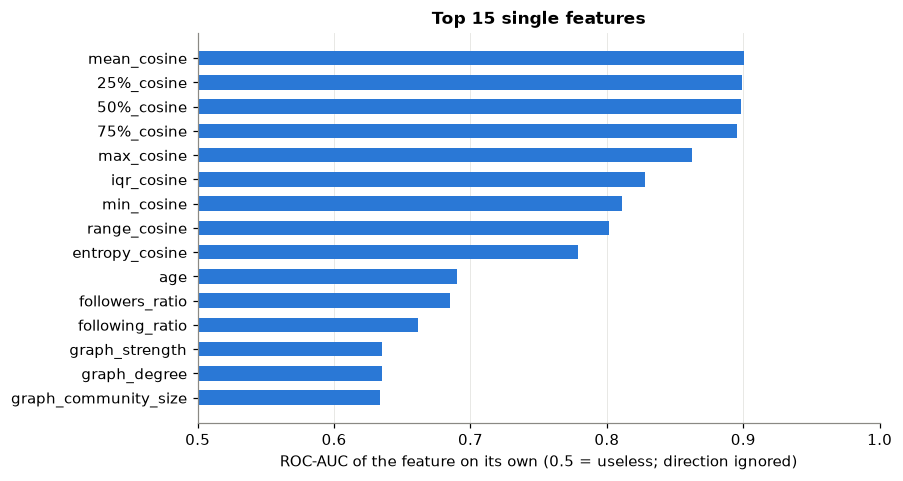

,feature,auc,separation,missing
70,mean_cosine,0.900,0.801,0.000
72,25%_cosine,0.899,0.799,0.000
73,50%_cosine,0.898,0.797,0.000
74,75%_cosine,0.895,0.790,0.000
75,max_cosine,0.862,0.724,0.000
77,iqr_cosine,0.828,0.655,0.000
71,min_cosine,0.811,0.623,0.000
76,range_cosine,0.801,0.602,0.000
78,entropy_cosine,0.778,0.557,0.000
3,age,0.310,0.380,0.000


In [14]:
feat = [c for c in acc.columns if c not in C.NON_FEATURE_COLS and c not in
        {"campaign", "n_campaigns", "community", "score"} and pd.api.types.is_numeric_dtype(acc[c])]
y = acc[C.COL_LABEL].to_numpy()
rows = []
for c in feat:
    x = acc[c].replace([np.inf, -np.inf], np.nan)
    ok = x.notna().to_numpy()
    auc = roc_auc_score(y[ok], x[ok]) if ok.sum() and y[ok].min() != y[ok].max() else np.nan
    rows.append({"feature": c, "auc": auc, "separation": abs(auc - .5) * 2, "missing": 1 - ok.mean()})
uni = pd.DataFrame(rows).sort_values("separation", ascending=False)
top = uni.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.feature, top.auc.sub(.5).abs() + .5, color=NORMAL, height=.6)
ax.set_xlim(.5, 1); ax.set_xlabel("ROC-AUC of the feature on its own (0.5 = useless; direction ignored)")
ax.set_title("Top 15 single features"); ax.grid(axis="y", visible=False)
plt.show()
uni.head(15)

**Finding.** The nine text-similarity statistics are the nine best single features (ROC-AUC 0.78–0.90). After them come account age, the follower ratios and the three network features (≈ 0.63–0.69). **No single non-text feature passes 0.70.**

**Decision.** Good separation needs **many weak signals combined, with interactions and thresholds** (e.g. *young* **and** *fast* **and** *similar text*). That favours tree ensembles (Random Forest, Gradient Boosting) over a linear model; we still train Logistic Regression as a baseline to prove it.

## 10 · Data quality — missing and infinite values

In [15]:
num = acc[feat]
quality = pd.DataFrame({"missing": num.isna().mean(), "infinite": np.isinf(num).mean()})
quality = quality[(quality.missing > 0) | (quality.infinite > 0)].sort_values("missing", ascending=False)
print(f"{len(quality)} of {len(feat)} features have missing or infinite values")
quality.head(15).style.format("{:.1%}")

0 of 79 features have missing or infinite values


,missing,infinite


In [16]:
(acc.assign(no_cosine=acc["mean_cosine"].isna(), no_network=acc["graph_degree"].fillna(0) == 0)
    .groupby(C.COL_LABEL)[["no_cosine", "no_network"]].mean().rename(index={0: "normal", 1: "IO"})
    .style.format("{:.1%}"))

,no_cosine,no_network
replier_label,,
normal,0.0%,97.7%
IO,0.0%,70.6%


**Finding.** The released file has **no missing and no infinite values** — but it has *placeholder zeros*: the cosine features are 0 for accounts with no comparison, and network features are 0 for the 97.7 % of normal accounts (70.6 % of IO) outside the network.

**Decisions.**
- The loader still turns ±∞ into missing values, because **user uploads** can contain them (ratios divided by 0).
- Gradient Boosting handles missing values natively; the Logistic Regression baseline gets **median imputation + standard scaling** inside its pipeline, fitted on training folds only (no leakage from the test campaign).
- No rows are dropped: an account with zeros is still a real account the model must score.

## 11 · Do campaigns look alike? (the reason for leave-one-campaign-out)

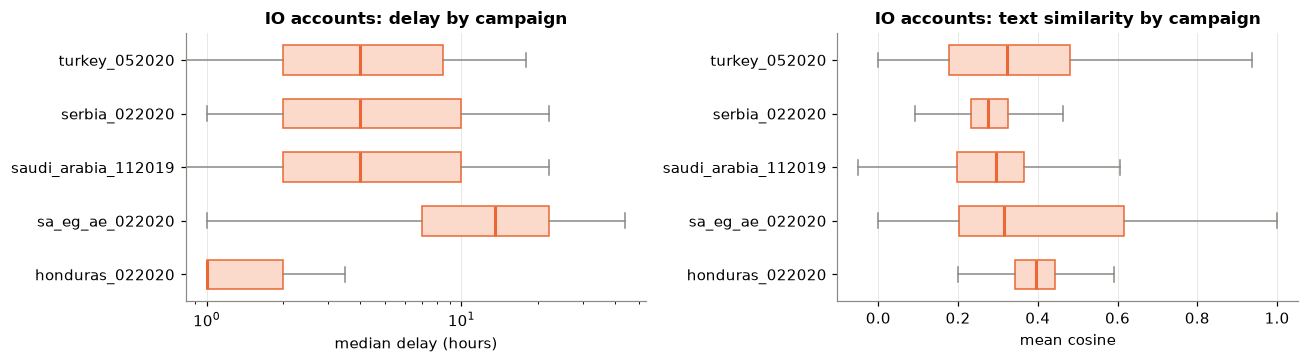

,50%_diff_min,mean_cosine,age,graph_degree
campaign_group,,,,
honduras_022020,1.000,0.395,0.118,0.000
sa_eg_ae_022020,13.500,0.315,4.671,0.000
saudi_arabia_112019,4.000,0.294,0.735,0.000
serbia_022020,4.000,0.274,0.595,0.000
turkey_052020,4.000,0.322,1.016,0.000


In [17]:
main = acc[acc.campaign_group != "other"]
io = main[main[C.COL_LABEL] == 1]
groups = sorted(io.campaign_group.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, col, xl in [(axes[0], "50%_diff_min", "median delay (hours)"), (axes[1], "mean_cosine", "mean cosine")]:
    data = [io.loc[io.campaign_group == g, col].dropna() for g in groups]
    ax.boxplot(data, vert=False, showfliers=False, widths=.55, patch_artist=True,
               boxprops=dict(facecolor="#fbd9cb", edgecolor=IO), medianprops=dict(color=IO, linewidth=2),
               whiskerprops=dict(color="#8a8984"), capprops=dict(color="#8a8984"))
    ax.set_yticks(range(1, len(groups) + 1), groups); ax.set_xlabel(xl); ax.grid(axis="y", visible=False)
    if col == "50%_diff_min": ax.set_xscale("log")
axes[0].set_title("IO accounts: delay by campaign"); axes[1].set_title("IO accounts: text similarity by campaign")
plt.tight_layout(); plt.show()
io.groupby("campaign_group")[["50%_diff_min", "mean_cosine", "age", "graph_degree"]].median()

**Finding.** Each operation has its own style. Median IO delay is **1 h** in Honduras but **13.5 h** in the Saudi/Egypt/UAE campaign; IO accounts in Honduras are **6 weeks** old (median 0.12 years), those in Saudi/Egypt/UAE **4.7 years**.

**Decision — the evaluation design.** If we split accounts at random, the model would see each campaign's style in training and look far better than it is. The real use is spotting a **new** operation, so we use **leave-one-campaign-out (LOCO)**: train on all campaigns but one, test on the one left out, repeat for each. For comparison, the paper-style random 1:1 split gives ROC-AUC 0.97 / F1 0.93 — numbers that do not hold on unseen campaigns.

## 12 · Redundant features

In [18]:
corr = acc[feat].sample(100_000, random_state=0).corr(method="spearman").abs()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False)
print(f"feature pairs with |Spearman| > 0.95: {(pairs > .95).sum()} of {len(pairs):,}")
pairs.head(10).to_frame("|spearman|")

feature pairs with |Spearman| > 0.95: 60 of 6,241


|spearman|
graph_degree        graph_strength              1.000
                    graph_community_size        1.000
graph_strength      graph_community_size        1.000
range_num_url       entropy_num_url             1.000
range_retweet_count entropy_retweet_count       1.000
mean_retweet_count  max_retweet_count           1.000
range_reply_count   entropy_reply_count         0.999
mean_num_url        max_num_url                 0.999
mean_reply_count    max_reply_count             0.999
mean_cosine         75%_cosine                  0.999

**Finding.** 60 feature pairs are almost identical (|Spearman| > 0.95): the three network features move together (they are all 0 outside the network), and statistics of the same quantity (`mean_cosine` vs `75%_cosine`) are near-copies.

**Decision.** Tree models are not hurt by redundant features, so we keep all 76 released features to stay comparable with the paper. Redundancy does make single-feature importance misleading, so **importance is measured per feature group** (permutation of the whole group). It is also one reason Logistic Regression trails.

## Summary — what the data told us, and what we did about it

| # | What we found | What we decided |
|---|---|---|
| 2 | IO accounts are **0.97 %** of all accounts | PR-AUC + precision@k, not accuracy; 10:1 downsampling in training only; rank for review instead of auto-labelling |
| 3 | IO share ranges **0.3 % → 14 %** across campaigns | Report per campaign; read PR-AUC against prevalence; headline = mean over campaigns |
| 4 | Viral targets reach 47 k replies | Network from target tweets only; skip tweets > 2,000 repliers; ≥ 3 shared tweets per link |
| 5 | `diff_min` is **hours**, not minutes (96.5 % match) | Use hours everywhere; the app rebuilds delays in hours |
| 5 | Timing differs only a little | Keep as one weak signal among several |
| 6 | Text similarity is the strongest signal (AUC 0.90); 80 % of normal accounts have a placeholder 0; without it PR-AUC falls 0.54 → 0.14 | Keep it and state the caveat; the simple model cannot rebuild it, so the app flags near-copied replies separately |
| 7 | IO accounts are young (0.5 vs 2.6 years) | Keep profile features; use age in the simple model |
| 8 | 29 % of IO vs 2.3 % of normal accounts reply in groups | Add network features (+0.04 PR-AUC); show groups in the app |
| 9 | No non-text feature alone passes AUC 0.70 | Non-linear tree models (RF, HGB), logistic regression as baseline |
| 10 | No NaN/∞ in the file, but placeholder zeros | ∞ → NaN for uploads; imputation + scaling for LogReg inside the pipeline |
| 11 | Each campaign has its own style | **Leave-one-campaign-out** evaluation |
| 12 | 60 near-duplicate feature pairs | Keep (trees tolerate it); explain importance by feature group |

Next: `docs/RESULTS.md` (how the models did) and `docs/REPORT.md` (every choice and its reason).